In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

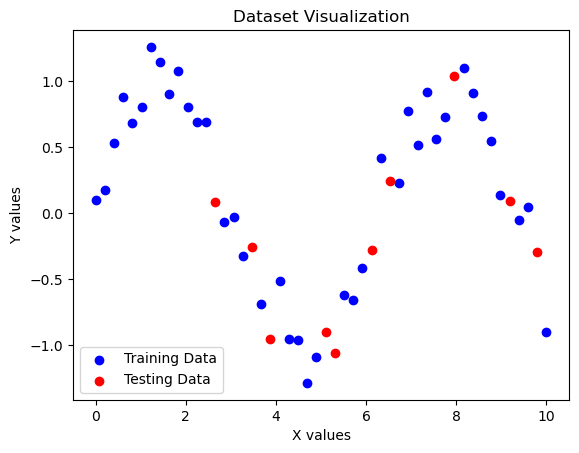

In [2]:
np.random.seed(42)

X = np.linspace(0, 10, 50).reshape(-1, 1)

y = np.sin(X).ravel() + np.random.normal(0, 0.2, 50)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Testing Data')

plt.title("Dataset Visualization")
plt.xlabel("X values")
plt.ylabel("Y values")
plt.legend()
plt.show()

In [3]:
degrees = [1, 4, 15]

models = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    models.append(model)

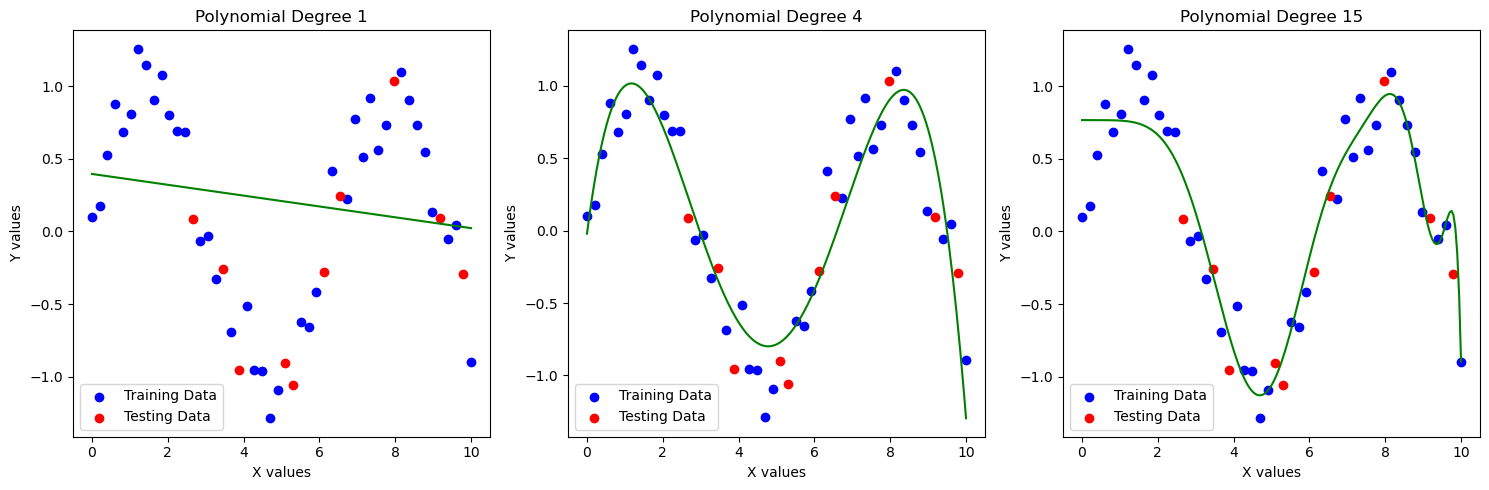

In [4]:
plt.figure(figsize=(15, 5))

for i, degree in enumerate(degrees):
    plt.subplot(1, 3, i + 1)

    plt.scatter(X_train, y_train, color='blue', label='Training Data')
    plt.scatter(X_test, y_test, color='red', label='Testing Data')

    X_curve = np.linspace(0, 10, 200).reshape(-1, 1)
    y_curve = models[i].predict(X_curve)

    plt.plot(X_curve, y_curve, color='green')

    plt.title(f"Polynomial Degree {degree}")
    plt.xlabel("X values")
    plt.ylabel("Y values")
    plt.legend()

plt.tight_layout()
plt.show()

In [5]:
train_errors = []
test_errors = []

for model in models:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_errors.append(mean_squared_error(y_train, train_pred))
    test_errors.append(mean_squared_error(y_test, test_pred))

print("Training Errors:", train_errors)
print("Testing Errors:", test_errors)

Training Errors: [0.4801112208805554, 0.06398777317963064, 0.056890382907026124]
Testing Errors: [0.5770033585253393, 0.0729955586212583, 0.044359297380329434]


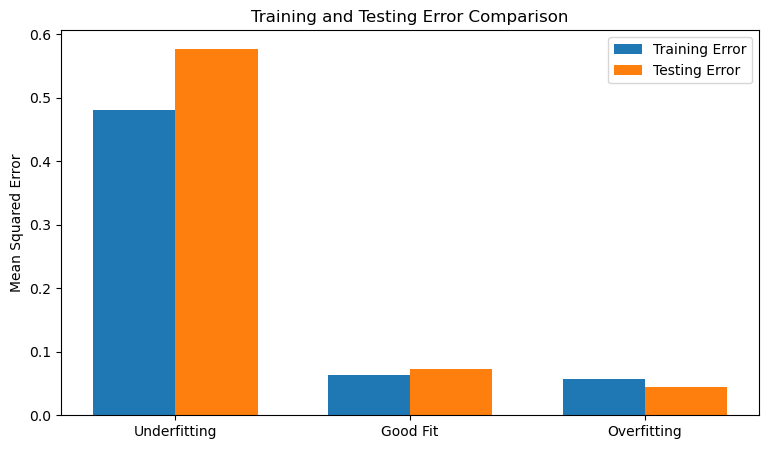

In [6]:
x = np.arange(len(degrees))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, train_errors, width, label='Training Error')
plt.bar(x + width/2, test_errors, width, label='Testing Error')

plt.xticks(x, ['Underfitting', 'Good Fit', 'Overfitting'])
plt.ylabel("Mean Squared Error")
plt.title("Training and Testing Error Comparison")
plt.legend()

plt.show()